In [1]:
import io
import datetime as datetime
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np

In [ ]:
folder_with_data = '../Data/Final-Data'

river_flow = pd.read_csv(folder_with_data + '/river-flow.csv')
river_flow['dateTime'] = pd.to_datetime(river_flow['dateTime'], errors='raise').dt.date
river_flow = river_flow.groupby('dateTime').mean().reset_index()

climate_variables = pd.read_csv(folder_with_data + '/atmospheric-variables.csv')
climate_variables['dateTime'] = pd.to_datetime(
    climate_variables['dateTime'],
    errors='raise'
)

numeric_cols = climate_variables.select_dtypes(include=np.number).columns
climate_variables[numeric_cols] = climate_variables[numeric_cols].interpolate(
    method='linear',
    limit_direction='both'
)

climate_variables['dateTime'] = climate_variables['dateTime'].dt.date

river_flow = river_flow.drop(columns='Unnamed: 0')

weather_data = pd.merge(
    climate_variables,
    river_flow,
    on='dateTime',
    how='inner'
)

weather_data = weather_data.iloc[:, [0,3,1,4,5,6,7,8,9,10,11,12,13]]

time_steps = 30
horizon = 7

numerical_columns = weather_data.select_dtypes(include=np.number).columns

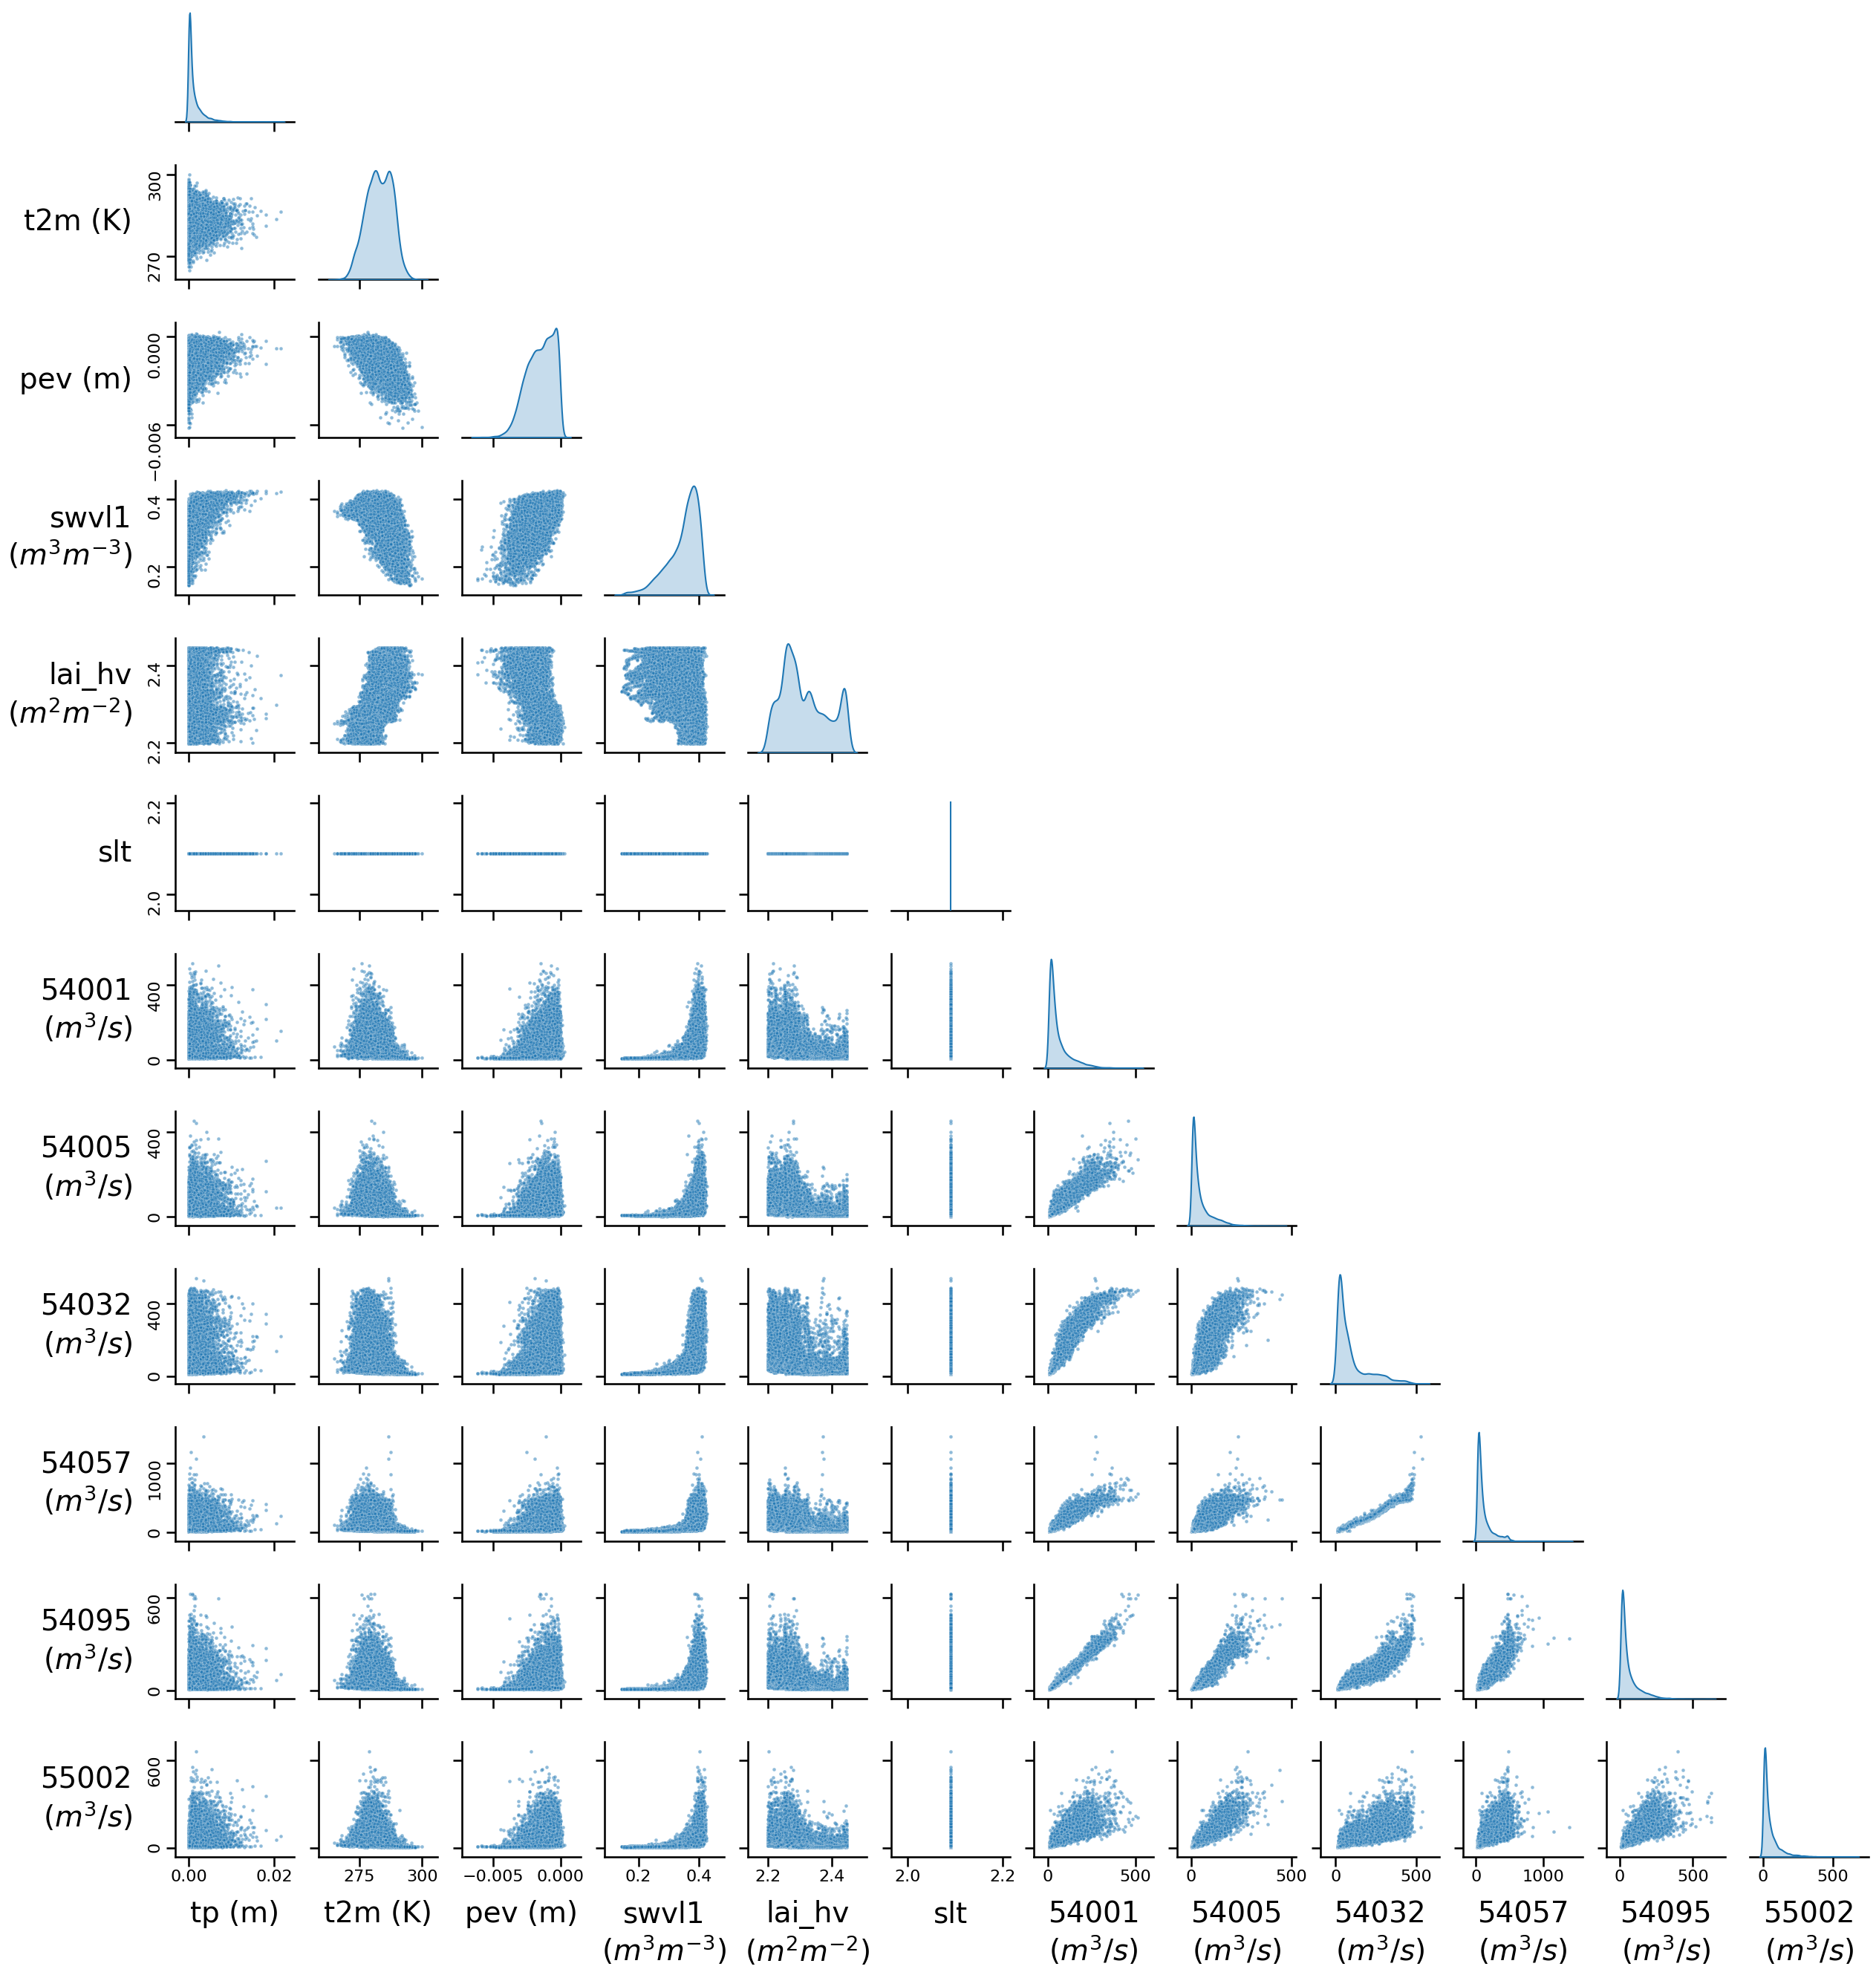

In [3]:
unit_mapping = {
    "gdf": "Gauged Flow\n($m^3/s$)",
    "tp": "tp (m)",
    "t2m": "t2m (K)",
    "pev": "pev (m)",
    "swvl1": "swvl1\n($m^3 m^{-3}$)",
    "slt": "slt",
    "lai_hv": "lai_hv\n($m^2 m^{-2}$)",
    "54001": "54001\n($m^3/s$)",
    "54005": "54005\n($m^3/s$)",
    "54032": "54032\n($m^3/s$)",
    "54057": "54057\n($m^3/s$)",
    "54095": "54095\n($m^3/s$)",
    "55002": "55002\n($m^3/s$)"
}

sns.set_context("talk", rc={
    "axes.labelsize": 28,        
    "xtick.labelsize": 16,       
    "ytick.labelsize": 16,       
    "axes.grid": False,          
    "axes.facecolor": "white",   
    "figure.facecolor": "white",
    "axes.labelweight": "bold",  
})

g = sns.pairplot(
    weather_data[1:], 
    kind='scatter', 
    diag_kind='kde', 
    corner=True,
    plot_kws={'s': 12, 'alpha': 0.5}  
)

for row_idx, row_axes in enumerate(g.axes):
    for col_idx, ax in enumerate(row_axes):
        if ax is not None:
            xlabel = ax.get_xlabel()
            ylabel = ax.get_ylabel()
            
            if xlabel in unit_mapping:
                ax.set_xlabel(unit_mapping[xlabel], labelpad=15)
            
            if ylabel in unit_mapping:
                ax.set_ylabel(
                    unit_mapping[ylabel], 
                    labelpad=15,       
                    rotation=0,
                    ha="right",        
                    va="center"
                )
            
            ax.tick_params(axis='x', rotation=0, labelsize=16)
            ax.tick_params(axis='y', rotation=90, labelsize=16)
            
            yticks = ax.get_yticks()
            if len(yticks) >= 2:
                ymin, ymax = ax.get_ylim()
                valid_ticks = [t for t in yticks if ymin <= t <= ymax]
                
                if len(valid_ticks) >= 2:
                    ax.set_yticks([valid_ticks[0], valid_ticks[-1]])
                else:
                    ax.set_yticks([ymin, ymax])
            
            ax.margins(0.1)

g.tight_layout()
plt.subplots_adjust(left=0.22, bottom=0.15, right=0.98, top=0.98)

plt.show()

In [4]:
def compute_event_durations(series, threshold):
    above = series > threshold
    
    durations = []
    current = 0

    for val in above:
        if val:
            current += 1
        else:
            if current > 0:
                durations.append(current)
            current = 0

    if current > 0:
        durations.append(current)

    return durations

In [5]:
event_stats = {}
station_cols = ['54001', '54005', '54032', '54057', '54095', '55002']
flow_data = weather_data[station_cols].copy()

q95 = {}
q25 = {}

for col in station_cols:
    q95[col] = np.percentile(flow_data[col], 95)
    q25[col] = np.percentile(flow_data[col], 25)

q95_df = pd.DataFrame.from_dict(q95, orient='index', columns=['Q95'])
q25_df = pd.DataFrame.from_dict(q25, orient='index', columns=['Q25'])
print(q95_df)
print(q25_df)

for col in station_cols:
    durations = compute_event_durations(weather_data[col], q95[col])

    event_stats[col] = durations

              Q95
54001  203.545821
54005  155.719163
54032  321.095833
54057  398.179783
54095  209.153058
55002  172.137037
             Q25
54001  17.598146
54005  10.801458
54032  26.035312
54057  36.509417
54095  17.786667
55002  12.971792


In [6]:
def compute_event_stats(flow_series):
    q95 = flow_series.quantile(0.95)

    high = (flow_series >= q95).astype(int)

    high_ratio = high.mean()
    normal_ratio = 1 - high_ratio

    lengths = []
    current = 0

    for v in high:
        if v == 1:
            current += 1
        elif current > 0:
            lengths.append(current)
            current = 0

    if current > 0:
        lengths.append(current)

    lengths = np.array(lengths) if len(lengths) > 0 else np.array([0])

    return {
        "q95": q95,
        "high_ratio": high_ratio,
        "normal_ratio": normal_ratio,
        "imbalance": high_ratio / (normal_ratio + 1e-8),
        "event_mean(days)": lengths.mean(),
        "event_median(days)": np.median(lengths),
        "event_max(days)": lengths.max(),
        "num_events": len(lengths)
    }

In [7]:
results = {}
for col in station_cols:
    results[col] = compute_event_stats(flow_data[col])
print(pd.DataFrame(results).T)

              q95  high_ratio  normal_ratio  imbalance  event_mean(days)  \
54001  203.545821    0.050059      0.949941   0.052697          4.872483   
54005  155.719163    0.050059      0.949941   0.052697          3.945652   
54032  321.095833    0.050059      0.949941   0.052697          6.152542   
54057  398.179783    0.050059      0.949941   0.052697          6.600000   
54095  209.153058    0.050059      0.949941   0.052697          4.840000   
55002  172.137037    0.050059      0.949941   0.052697          2.452703   

       event_median(days)  event_max(days)  num_events  
54001                 4.0             24.0       149.0  
54005                 3.0             18.0       184.0  
54032                 4.0             27.0       118.0  
54057                 5.0             27.0       110.0  
54095                 4.0             24.0       150.0  
55002                 2.0             13.0       296.0  


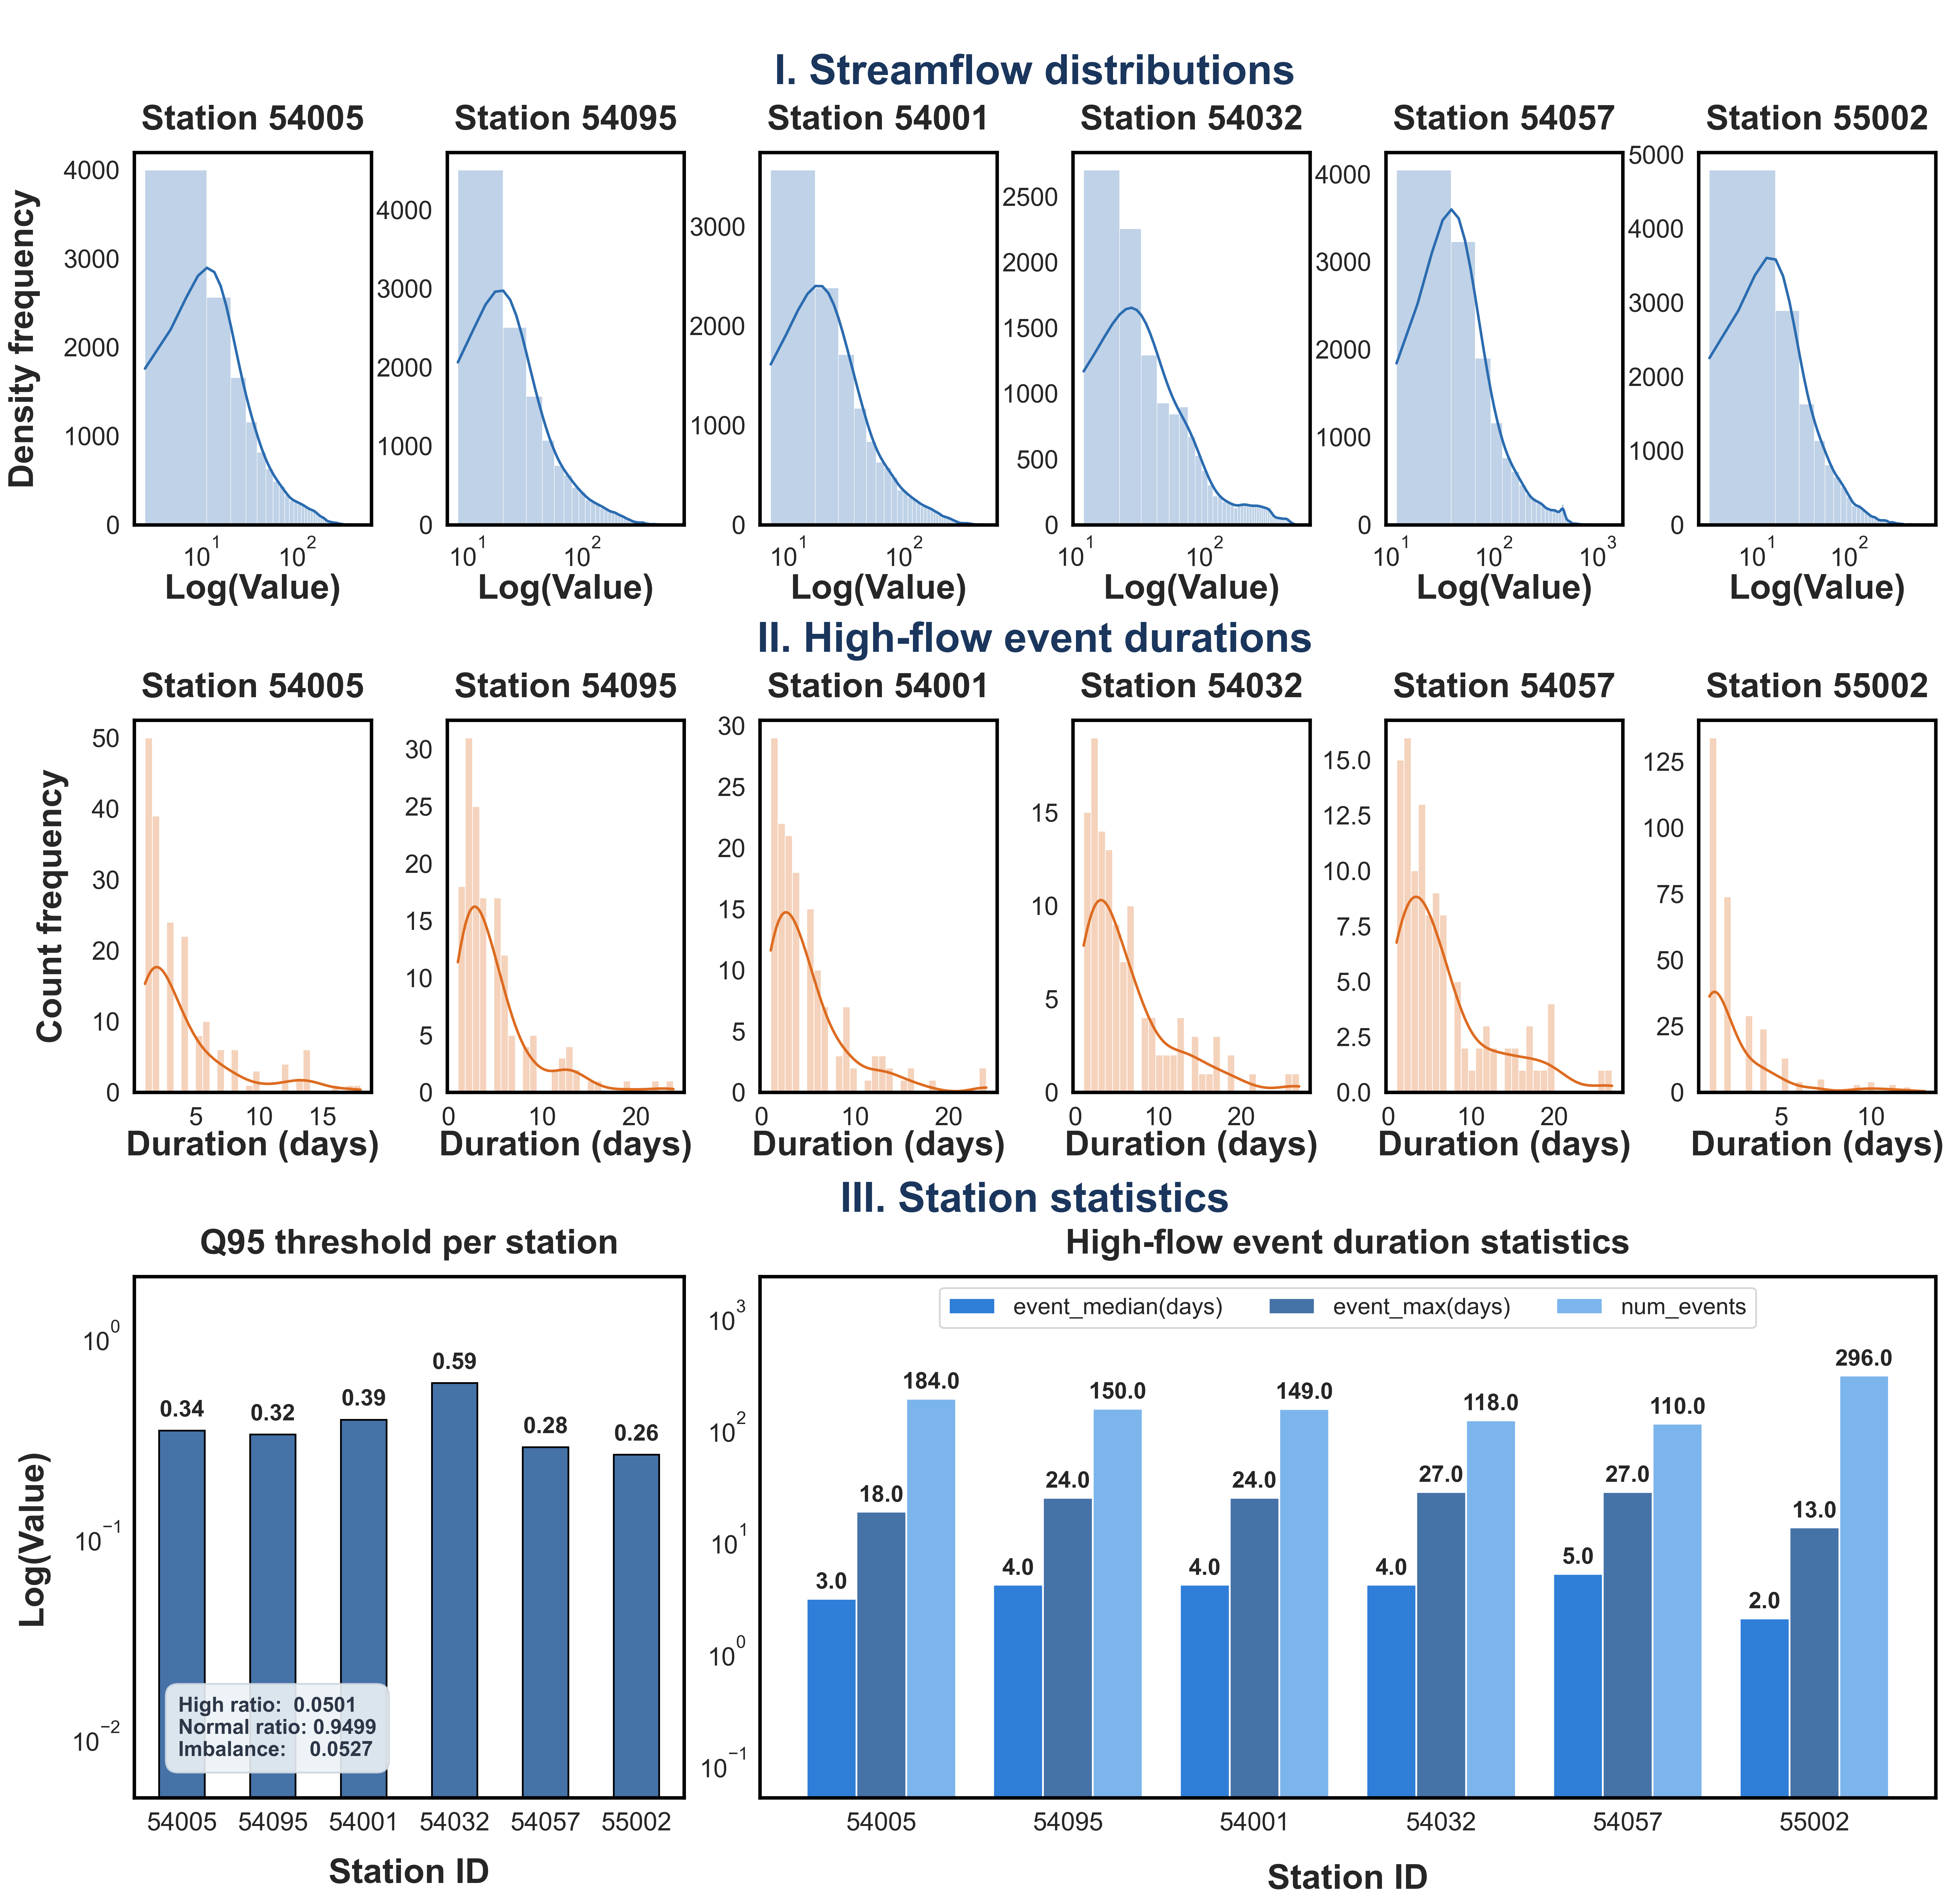

In [8]:

data = """
station q95 high_ratio normal_ratio imbalance event_mean(days) event_median(days) event_max(days) num_events
54005 0.340025 0.050059 0.949941 0.052697 3.945652 3.0 18.0 184.0
54095 0.324988 0.050059 0.949941 0.052697 4.840000 4.0 24.0 150.0
54001 0.385486 0.050059 0.949941 0.052697 4.872483 4.0 24.0 149.0
54032 0.587247 0.050059 0.949941 0.052697 6.152542 4.0 27.0 118.0
54057 0.280661 0.050059 0.949941 0.052697 6.600000 5.0 27.0 110.0
55002 0.257538 0.050059 0.949941 0.052697 2.452703 2.0 13.0 296.0
"""
df = pd.read_csv(io.StringIO(data.strip()), sep=r"\s+")
df["station"] = df["station"].astype(str)

station_cols = ["54005", "54095", "54001", "54032", "54057", "55002"]
desired_order = station_cols
df_station_ordered = df.set_index("station").reindex(desired_order)

station_q95 = df_station_ordered["q95"]

p = ["#0d233a", "#2f7ed8", "#4572a7", "#7cb5ec", "#b5cae1"]

sns.set_style("white")

plt.rcParams.update({
    'font.size': 22,
    'axes.labelsize': 30,
    'axes.titlesize': 30,
    'xtick.labelsize': 22,
    'ytick.labelsize': 22,
    'figure.titlesize': 42,
    'axes.grid': False,          
    'axes.facecolor': 'white',  
    'figure.facecolor': 'white'
})

fig = plt.figure(figsize=(28, 28), dpi=300)

gs = fig.add_gridspec(
    nrows=6, ncols=6, 
    height_ratios=[0.25, 1.0, 0.25, 1.0, 0.22, 1.4],
    wspace=0.32, hspace=0.20
)

def format_axis(ax, title_text, x_label="", y_label="", pad=20, labelpad=20, log=False):
    if title_text:
        ax.set_title(title_text, fontweight="bold", pad=pad)
    ax.set_xlabel(x_label, labelpad=labelpad, fontweight="bold")
    ax.set_ylabel(y_label, labelpad=20, fontweight="bold")
    if log:
        ax.set_xscale("log")

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(3)

def create_section_header(gs_pos, text):
    ax = fig.add_subplot(gs_pos)
    ax.text(0.5, 0.3, text, ha='center', va='center', fontsize=36, fontweight='bold', color='#1a365d')
    ax.axis('off')
    return ax

create_section_header(gs[0, :], "I. Streamflow distributions")

for idx, col in enumerate(station_cols):
    ax_dist = fig.add_subplot(gs[1, idx])
    sns.histplot(weather_data[col], bins=50, kde=True, ax=ax_dist, alpha=0.3, color="#2b6cb0")
    y_lab = "Density frequency" if idx == 0 else ""
    format_axis(ax_dist, f"Station {col}", x_label="Log(Value)",y_label=y_lab,labelpad=2,log=True)

create_section_header(gs[2, :], "II. High-flow event durations")

for idx, col in enumerate(station_cols):
    ax_dur = fig.add_subplot(gs[3, idx])
    sns.histplot(event_stats[col], bins=30, kde=True, ax=ax_dur, alpha=0.3, color="#dd6b20")
    y_lab = "Count frequency" if idx == 0 else ""
    format_axis(ax_dur, f"Station {col}", x_label="Duration (days)", y_label=y_lab, pad=20, labelpad=0)

create_section_header(gs[4, :], "III. Station statistics")

ax_shared = fig.add_subplot(gs[5, 0:2])
bars_shared = ax_shared.bar(
    station_q95.index, station_q95.values,
    color="#4572a7", width=0.5, edgecolor="black", linewidth=1.5
)
ax_shared.set_yscale("log")
ax_shared.set_ylim(bottom=0.005, top=2.0)
format_axis(ax_shared, "Q95 threshold per station", "Station ID", "Log(Value)")
ax_shared.tick_params(axis="x", labelrotation=0)

for bar in bars_shared:
    yval = bar.get_height()
    ax_shared.text(
        bar.get_x() + bar.get_width() / 2.0, yval * 1.12,
        f"{yval:.2f}", ha="center", va="bottom", fontsize=20, fontweight="bold"
    )

info_text = (
    f"High ratio:  {df['high_ratio'].iloc[0]:.4f}\n"
    f"Normal ratio: {df['normal_ratio'].iloc[0]:.4f}\n"
    f"Imbalance:    {df['imbalance'].iloc[0]:.4f}"
)
ax_shared.text(
    0.08, 0.08, info_text, transform=ax_shared.transAxes,
    fontsize=18, fontweight="bold", color="#2d3748",
    bbox=dict(boxstyle="round,pad=0.6", facecolor="#edf2f7", edgecolor="#cbd5e0", alpha=0.9)
)

ax_metrics = fig.add_subplot(gs[5, 2:6])
station_cols_metrics = ["event_median(days)", "event_max(days)", "num_events"]
df_station_ordered[station_cols_metrics].plot(kind="bar", ax=ax_metrics, width=0.8, color=p[1:])
ax_metrics.set_yscale("log")
ax_metrics.set_ylim(bottom=0.05, top=ax_metrics.get_ylim()[1] * 6)
format_axis(ax_metrics, "High-flow event duration statistics", "Station ID", "", labelpad=25)
ax_metrics.legend(fontsize=20, loc="upper center", ncols=3, frameon=True)
ax_metrics.tick_params(axis="x", rotation=0)

for container in ax_metrics.containers:
    labels = [f"{v:.1f}" if v >= 1 else f"{v:.2f}" for v in container.datavalues]
    ax_metrics.bar_label(container, labels=labels, fontsize=20, padding=5, fontweight="bold")

plt.show()

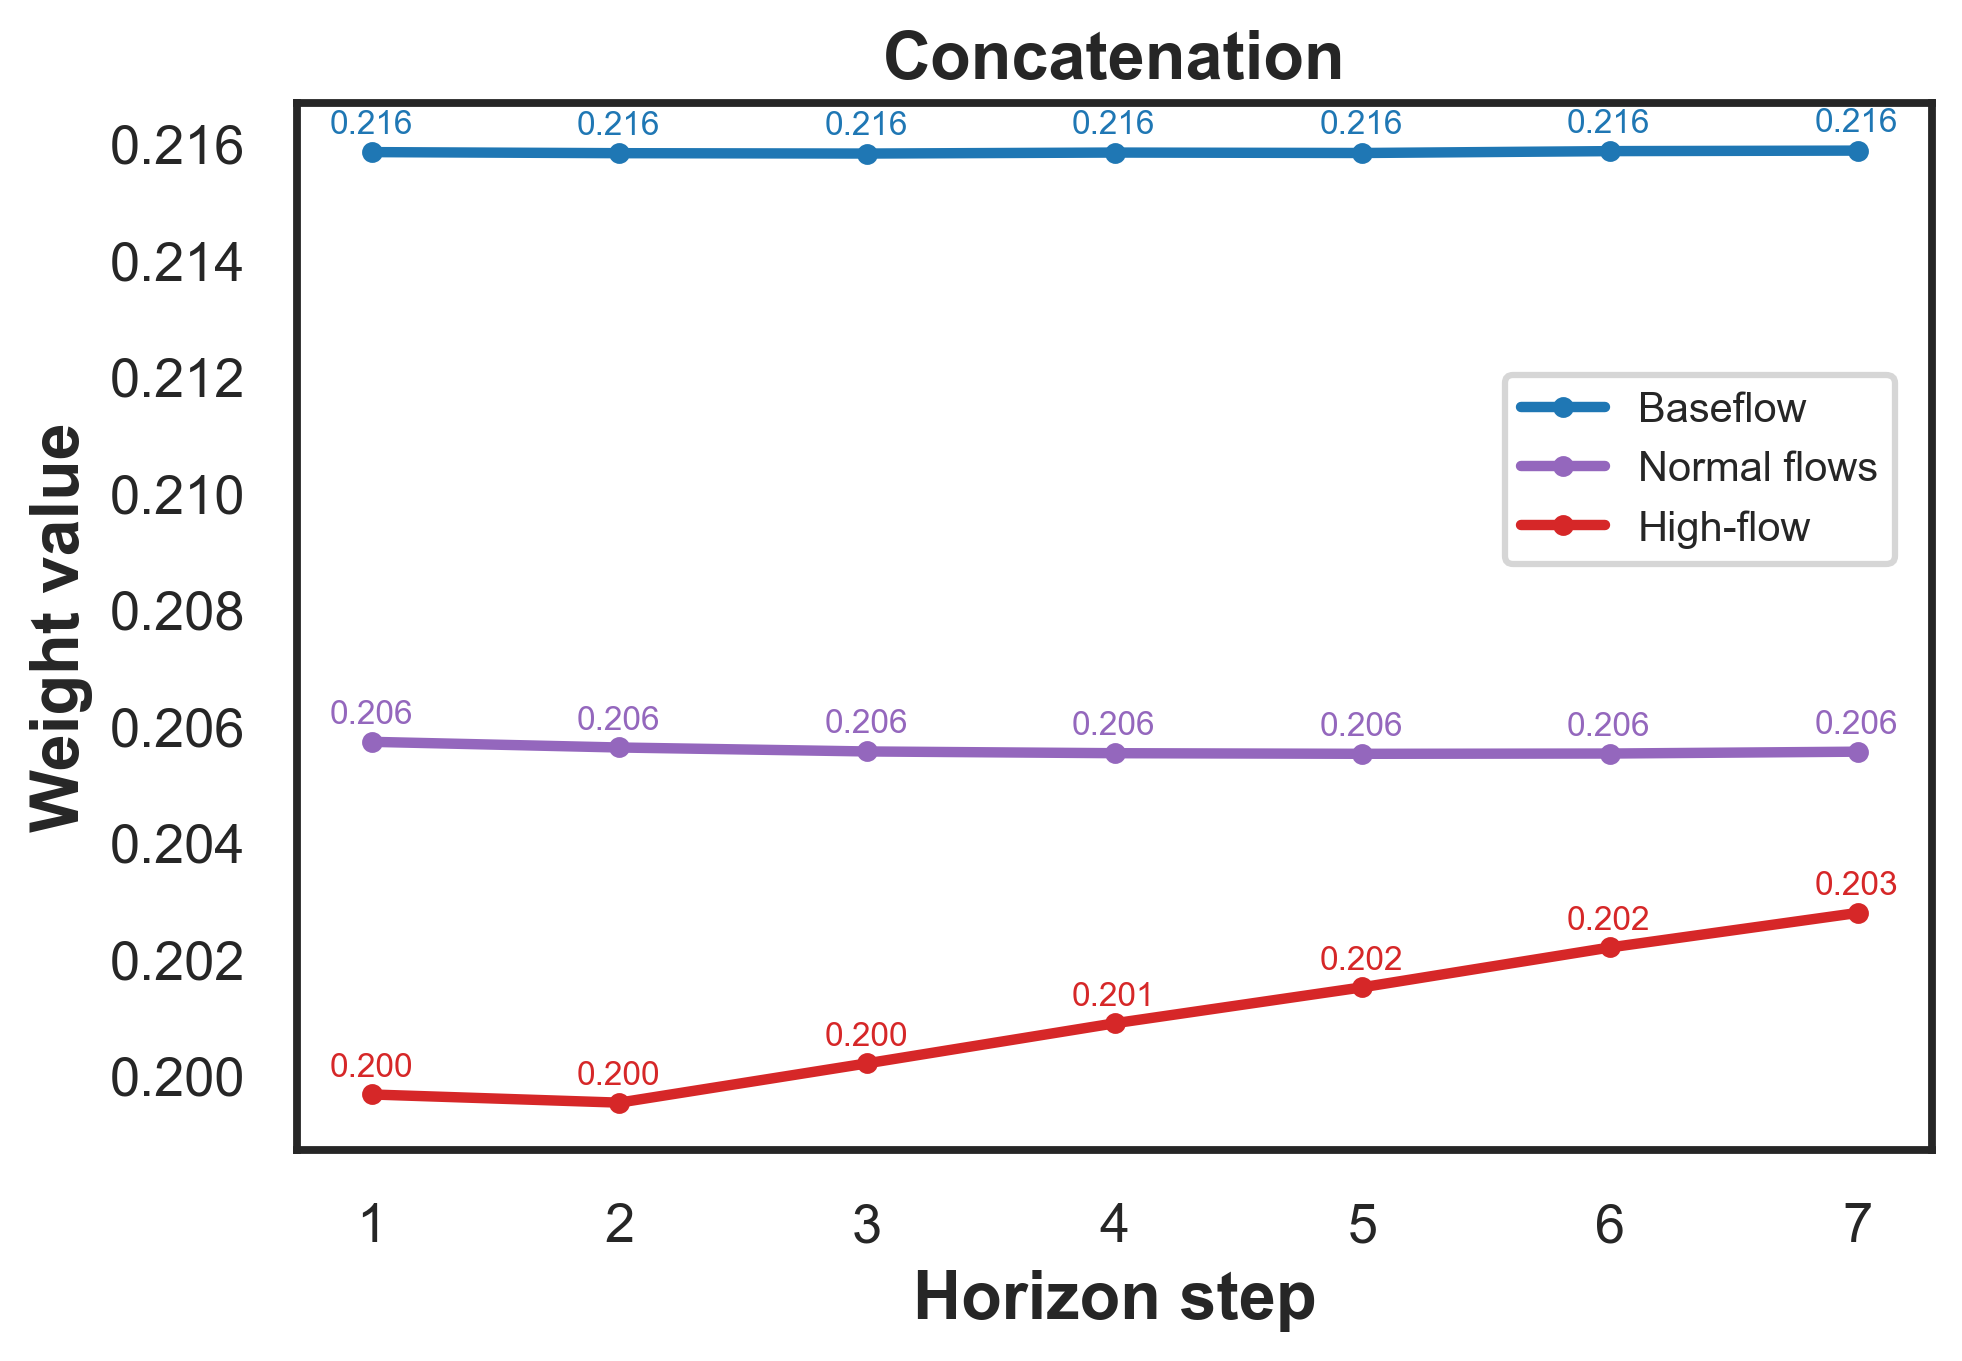

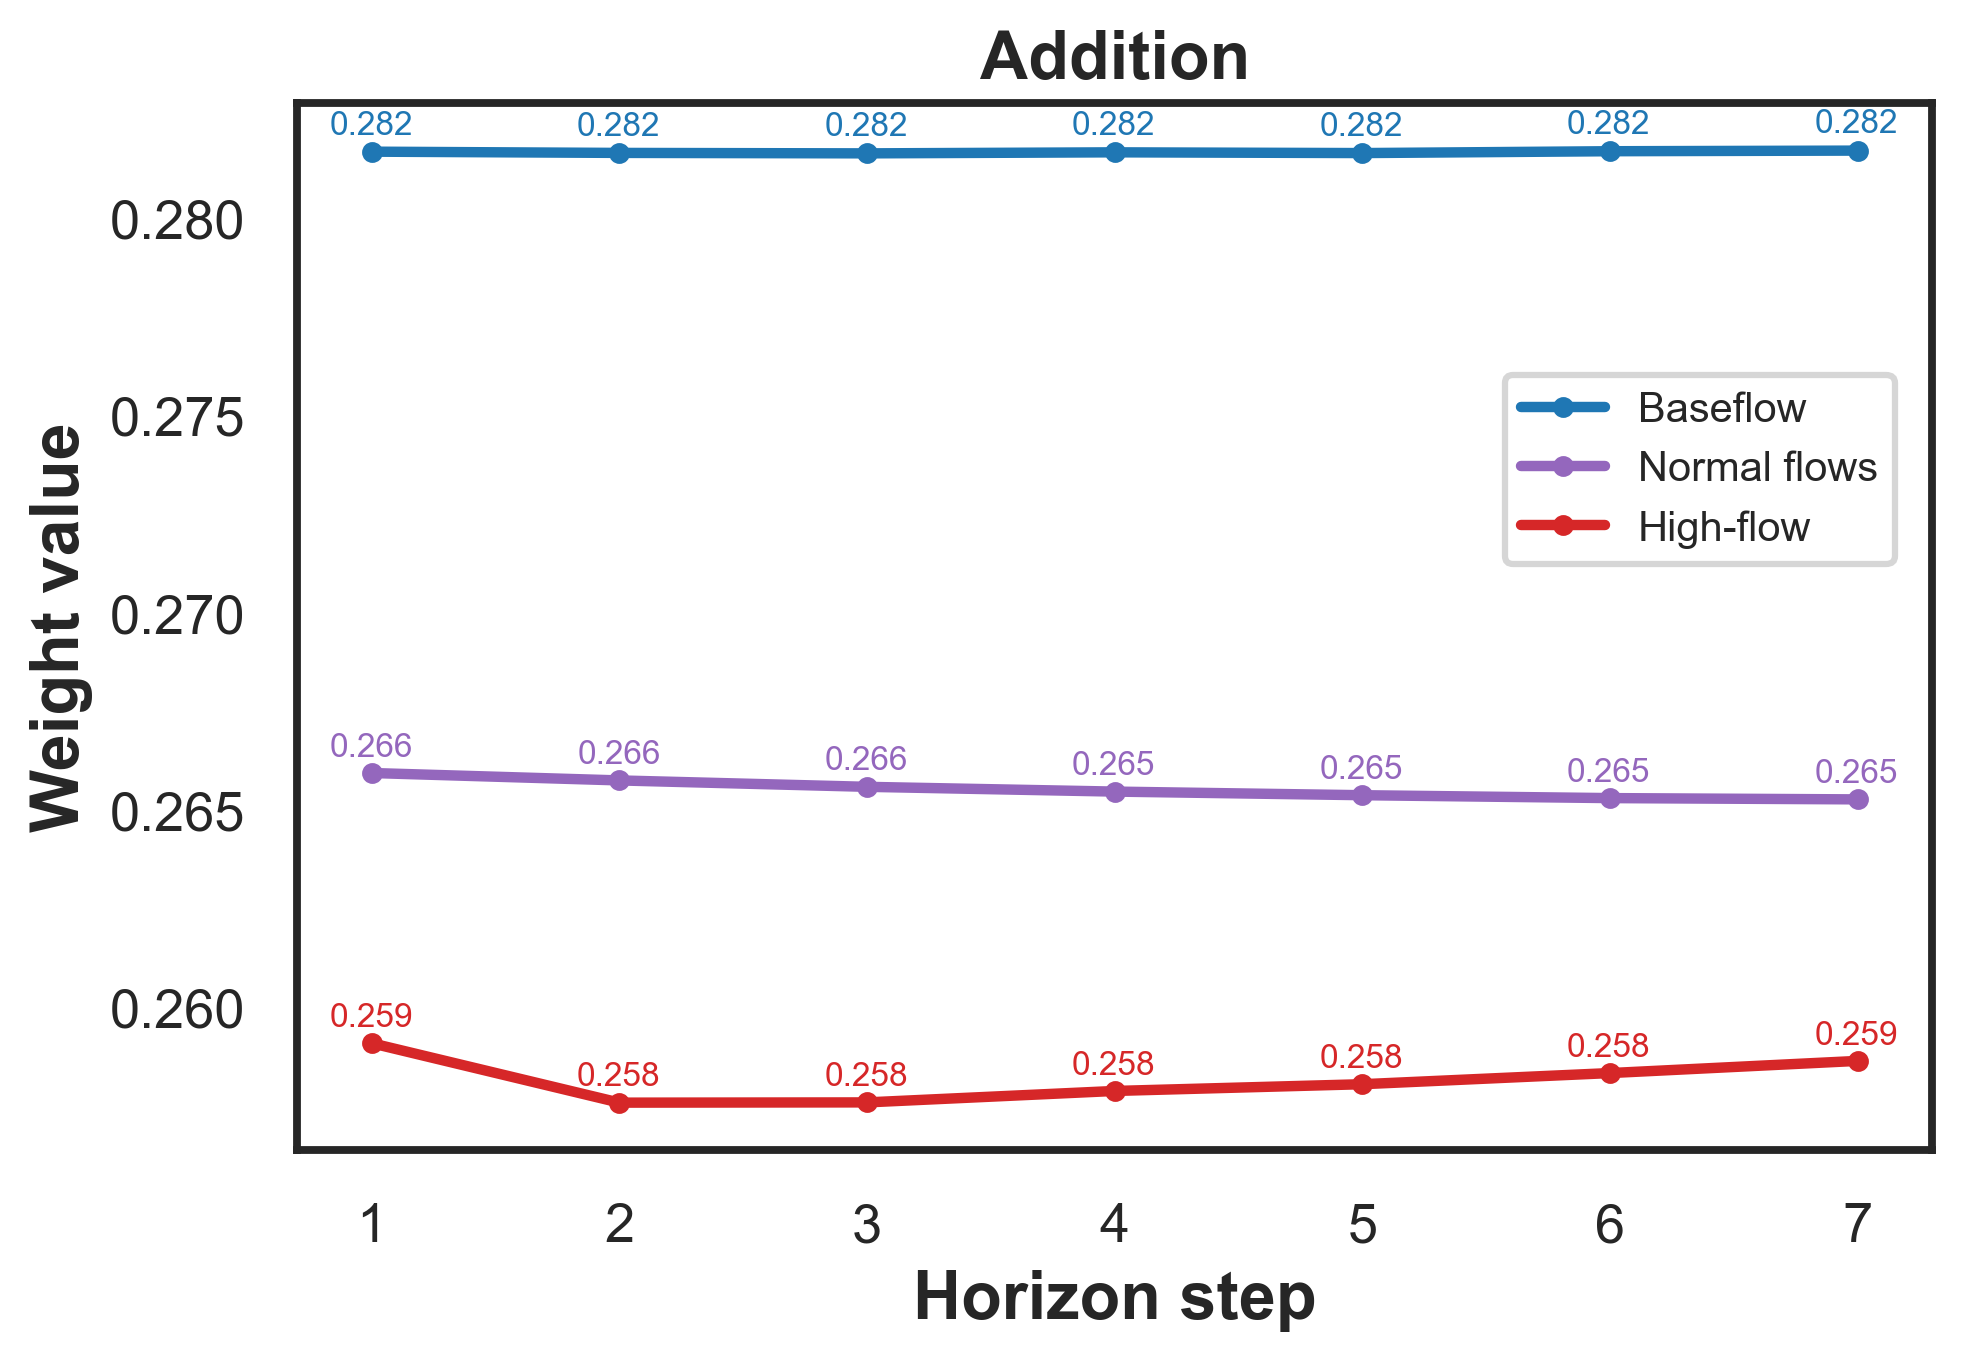

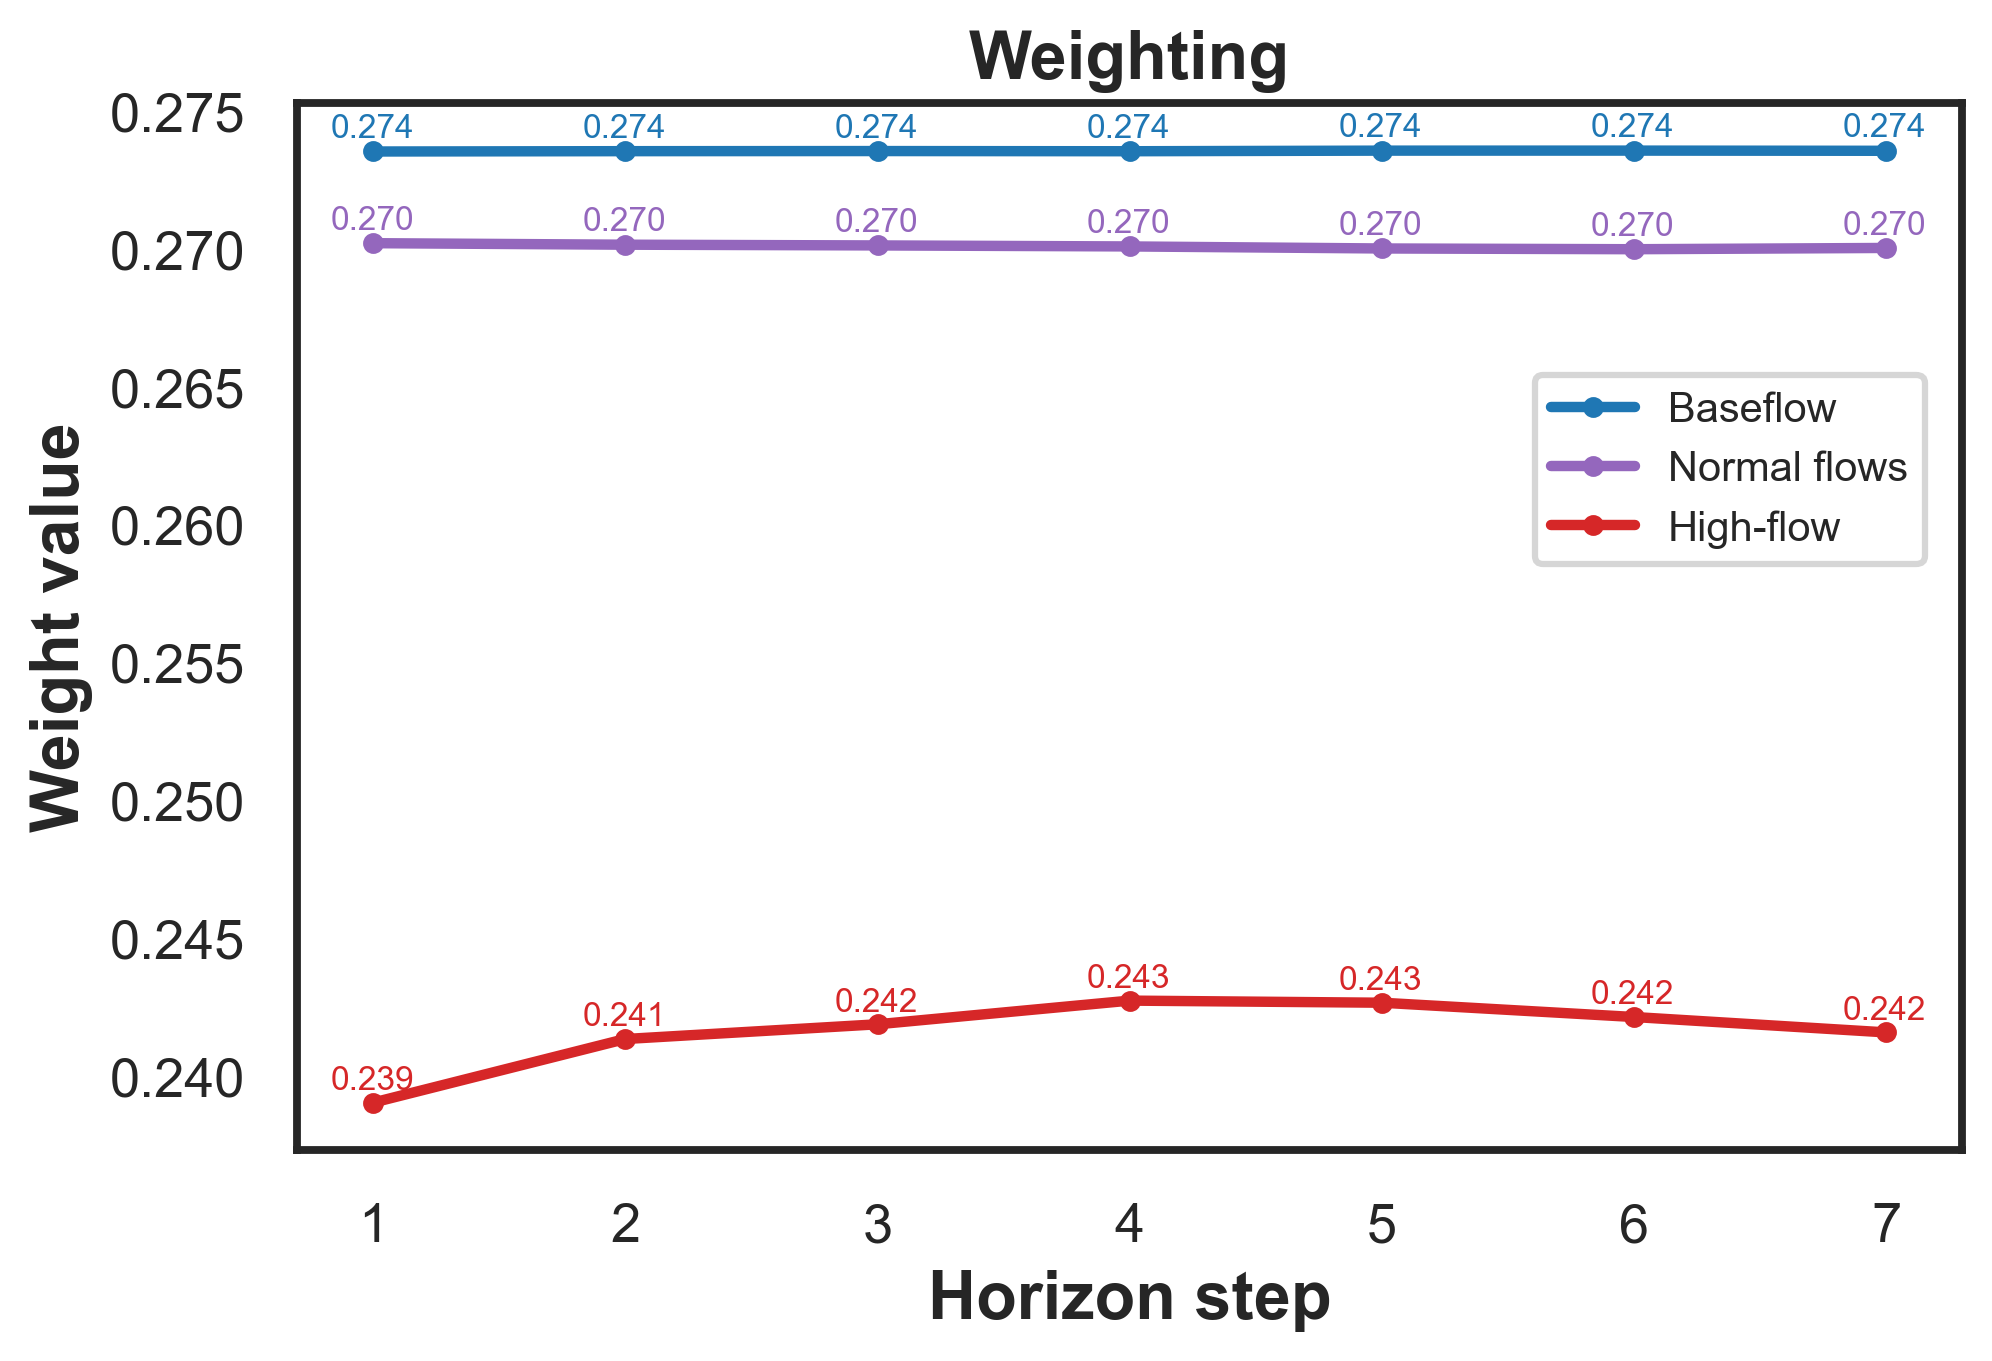

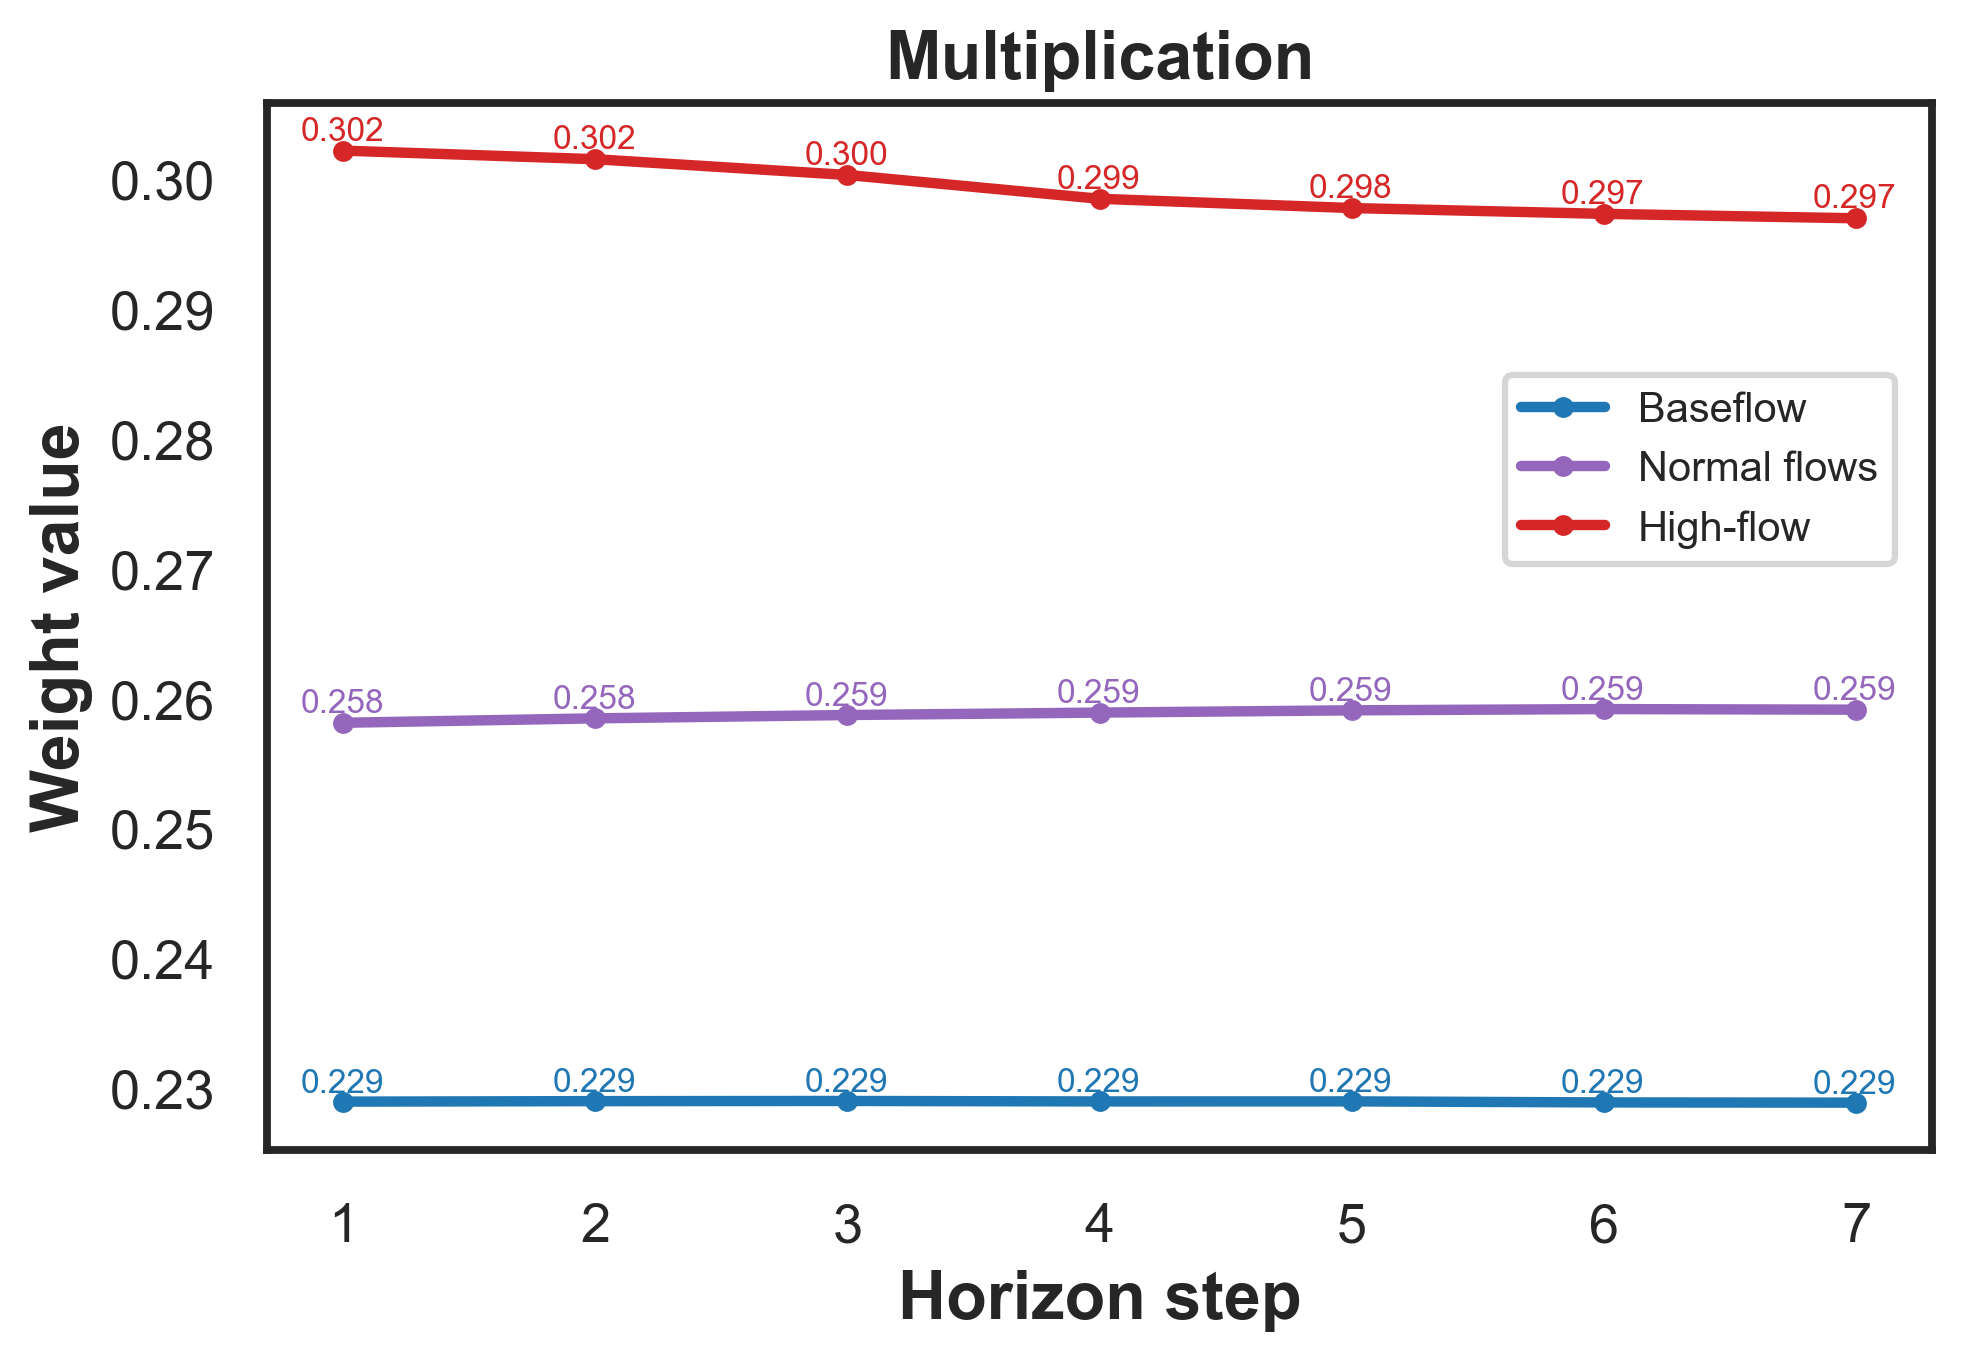

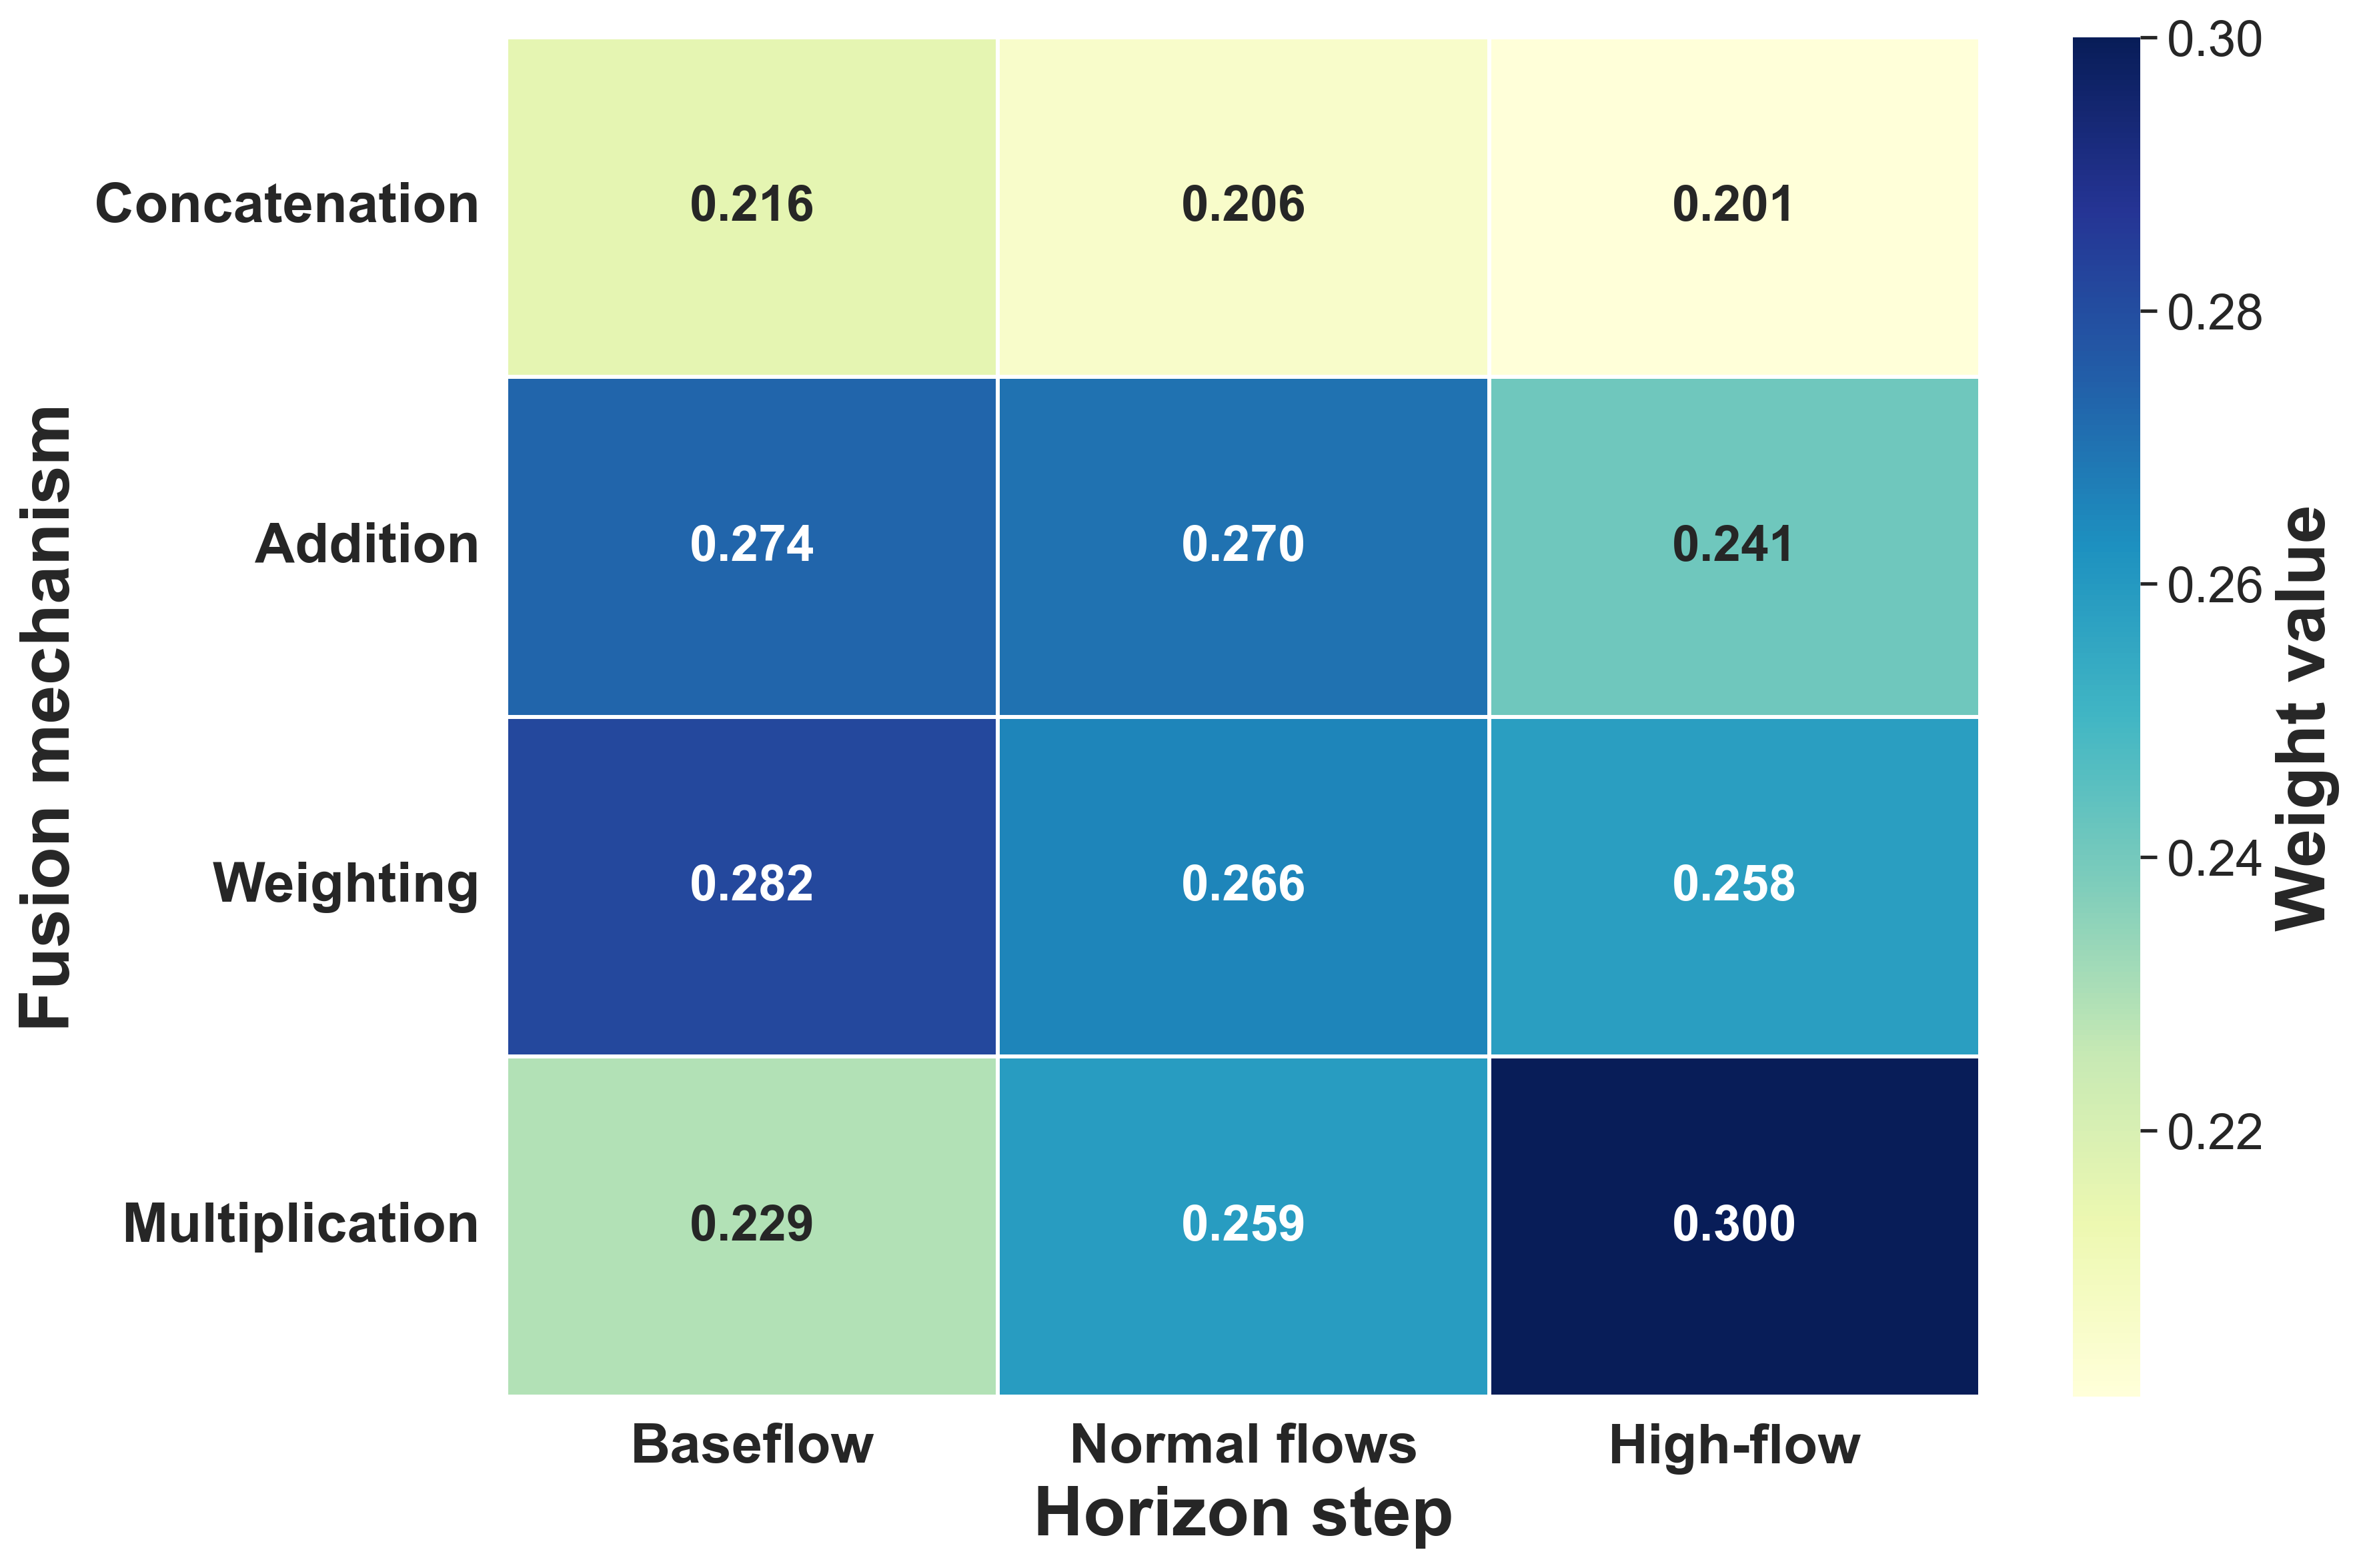

In [ ]:
run_idx = 0 
Q = np.load('Saved-from-run-models/full-predictions-encdec-mul-dyn1-4-fusion-weights.npy')
Q_full = Q.squeeze(axis=0)
gate_weights = np.load('Saved-from-run-models/fusion-weights.npy')
gate_weights = np.mean(gate_weights, axis=2)

num_test_samples = gate_weights.shape[0]  
Q = Q_full[-num_test_samples:] 

Q_regime = np.mean(Q_full, axis=2) 

modality_labels = ["Concatenation", "Addition", "Weighting", "Multiplication"]
num_modalities = gate_weights.shape[-1]
if len(modality_labels) != num_modalities:
    modality_labels = [f"Modality {i+1}" for i in range(num_modalities)]

baseflow_mask  = Q_regime < np.percentile(Q_regime, 5)
peak_mask      = Q_regime > np.percentile(Q_regime, 95)
normal_flows = (~baseflow_mask) & (~peak_mask)

if gate_weights.ndim == 3:
    baseflow_weights = gate_weights[baseflow_mask]
    peak_weights     = gate_weights[peak_mask]
    normals_weights = gate_weights[normal_flows]
    
    mean_baseflow  = np.mean(baseflow_weights, axis=0) if len(baseflow_weights) > 0 else np.zeros(num_modalities)
    mean_peak      = np.mean(peak_weights, axis=0)     if len(peak_weights) > 0 else np.zeros(num_modalities)
    mean_normals = np.mean(normals_weights, axis=0) if len(normals_weights) > 0 else np.zeros(num_modalities)
    temporal_baseflow = np.array([np.mean(gate_weights[:, t, :][baseflow_mask[:, t]], axis=0) for t in range(Q.shape[1])])
    temporal_peak     = np.array([np.mean(gate_weights[:, t, :][peak_mask[:, t]], axis=0) for t in range(Q.shape[1])])
    temporal_normals = np.array([np.mean(gate_weights[:, t, :][normal_flows[:, t]], axis=0) for t in range(Q.shape[1])])
else: 
    sample_baseflow  = np.any(baseflow_mask, axis=1)
    sample_peak      = np.any(peak_mask, axis=1)
    sample_normals = np.any(normal_flows, axis=1)

    mean_baseflow  = np.mean(gate_weights[sample_baseflow], axis=0)
    mean_peak      = np.mean(gate_weights[sample_peak], axis=0)
    mean_normals = np.mean(gate_weights[sample_normals], axis=0)

if gate_weights.ndim == 3:
    
    horizon_axis = np.arange(1, Q.shape[1] + 1)
    
    for m in range(num_modalities):
        plt.figure(figsize=(7, 5), dpi=300)
        
        plt.plot(horizon_axis, temporal_baseflow[:, m], label='Baseflow', linewidth=2.5, color='#1f77b4', marker='o',markersize=4)
        plt.plot(horizon_axis, temporal_normals[:, m], label='Normal flows', linewidth=2.5, color='#9467bd', marker='o',markersize=4)
        plt.plot(horizon_axis, temporal_peak[:, m], label='High-flow', linewidth=2.5, color='#d62728', marker='o',markersize=4)

        for x, y_bf, y_nf, y_pf in zip(horizon_axis, temporal_baseflow[:, m], temporal_normals[:, m], temporal_peak[:, m]):
            plt.text(x-(x*0.001), y_bf +(y_bf*0.001) , f'{y_bf:.3f}', ha='center', va='bottom', fontsize=8, color='#1f77b4')
            plt.text(x-(x*0.001), y_nf +(y_nf*0.001) , f'{y_nf:.3f}', ha='center', va='bottom', fontsize=8, color='#9467bd')
            plt.text(x-(x*0.001), y_pf +(y_pf*0.001) , f'{y_pf:.3f}', ha='center', va='bottom', fontsize=8, color='#d62728')

        plt.title(f'{modality_labels[m]}', fontsize=16, fontweight='bold')
        plt.xlabel('Horizon step', fontsize=16, fontweight='bold')
        plt.ylabel('Weight value', fontsize=16, fontweight='bold')
        plt.legend(fontsize=10, loc='center right',bbox_to_anchor=(0.99, 0.65))
        plt.xticks(rotation=0, fontsize=13)
        plt.yticks(rotation=0, fontsize=13)
        plt.tight_layout()
        plt.savefig(f"temporal_gate_{modality_labels[m].replace(' ', '_')}.png")

heatmap_data = pd.DataFrame({
    'Baseflow': mean_baseflow,
    'Normal flows': mean_normals,
    'High-flow': mean_peak,
}, index=["Concatenation", "Weighting", "Addition", "Multiplication"])
heatmap_data = heatmap_data.reindex(modality_labels)
heatmap_data.fillna(0, inplace=True)

plt.figure(figsize=(12, 8), dpi=300)
sns.set_theme(style='white')

ax = sns.heatmap(
    heatmap_data, 
    annot=True, 
    fmt=".3f", 
    cmap="YlGnBu", 
    linewidths=1, 
    cbar_kws={'label': 'Weight value'},
    annot_kws={"size": 18, "weight": "bold"}
)

cbar = ax.collections[0].colorbar
cbar.ax.yaxis.label.set_fontweight('bold')
cbar.ax.yaxis.label.set_fontsize(25)
cbar.ax.tick_params(labelsize=18)
ax.set_xlabel("Horizon step", fontsize=25, fontweight="bold")
ax.set_ylabel("Fusion mechanism", fontsize=25, fontweight="bold")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0, fontsize=20, fontweight="bold")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=20, fontweight="bold")

plt.xticks(fontsize=20)
plt.yticks(rotation=0, fontsize=20)
plt.tight_layout()

plt.savefig("fw-summary.png")
plt.show()